In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from collections import Counter

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
import os

PROJECT_PATH = os.path.expanduser("~/Potato_Disease_Detection")

print("Project Path:", PROJECT_PATH)
print("Project Exists:", os.path.exists(PROJECT_PATH))
print("\nProject Contents:")

if os.path.exists(PROJECT_PATH):
    print(os.listdir(PROJECT_PATH))
else:
    print("Project folder not found!")

Project Path: /Users/siddharth/Potato_Disease_Detection
Project Exists: True

Project Contents:
['test_images', '.DS_Store', 'dataset', 'models', '.ipynb_checkpoints', 'Potato_Disease_Detection.ipynb']


In [3]:
DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")

classes = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

for class_name in classes:

    folder_path = os.path.join(DATASET_PATH, class_name)

    if os.path.exists(folder_path):
        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{class_name}: {len(images)} images")
    else:
        print(f"{class_name}: Folder not found")

Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images


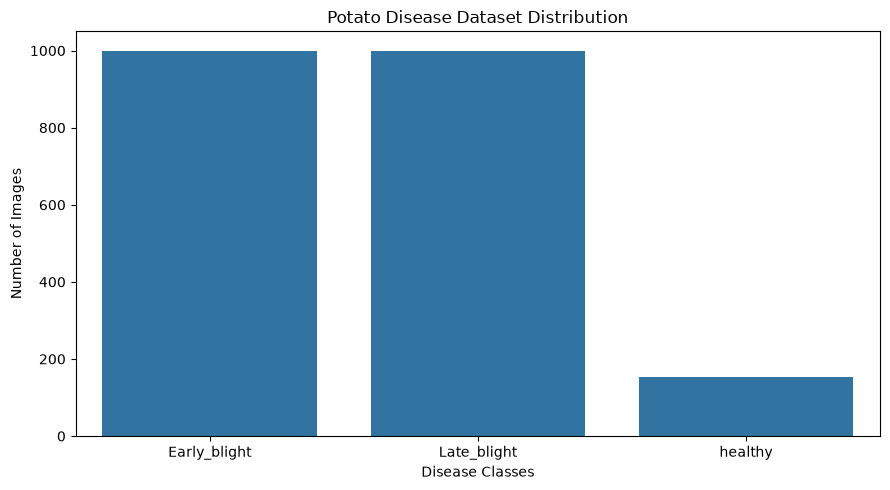

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

class_counts = {}

for class_name in classes:

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[class_name.replace("Potato___", "")] = len(image_files)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=list(class_counts.keys()),
    y=list(class_counts.values())
)

plt.title("Potato Disease Dataset Distribution")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

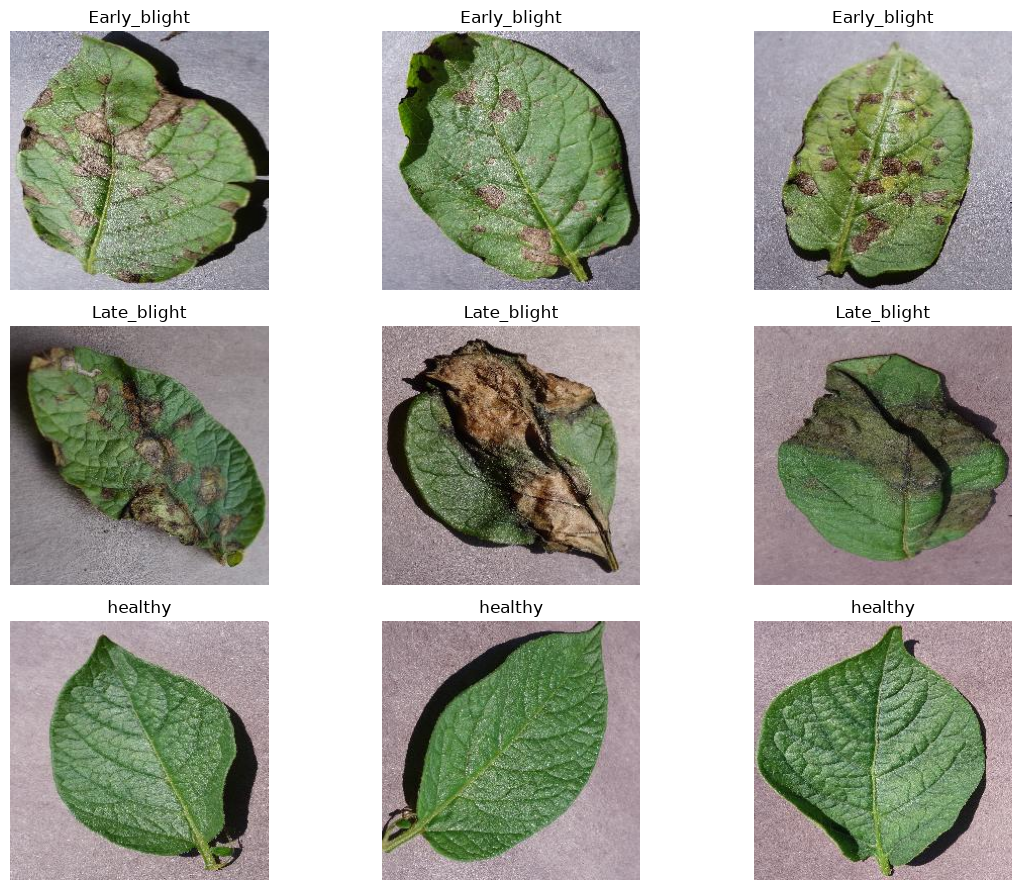

In [5]:
from PIL import Image
import random

plt.figure(figsize=(12, 9))

for i, class_name in enumerate(classes):

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected_images = random.sample(image_files, 3)

    for j, image_file in enumerate(selected_images):

        image_path = os.path.join(folder_path, image_file)

        img = Image.open(image_path)

        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(class_name.replace("Potato___", ""))
        plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
image_dimensions = []

for class_name in classes:

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image_file in image_files:

        image_path = os.path.join(folder_path, image_file)

        with Image.open(image_path) as img:
            image_dimensions.append(img.size)

dimension_df = pd.DataFrame(
    image_dimensions,
    columns=["Width", "Height"]
)

print(dimension_df.describe())

print("\nUnique image dimensions:")
print(dimension_df.value_counts().head(10))

        Width  Height
count  2152.0  2152.0
mean    256.0   256.0
std       0.0     0.0
min     256.0   256.0
25%     256.0   256.0
50%     256.0   256.0
75%     256.0   256.0
max     256.0   256.0

Unique image dimensions:
Width  Height
256    256       2152
Name: count, dtype: int64


In [7]:
corrupted_images = []

for class_name in classes:

    folder_path = os.path.join(DATASET_PATH, class_name)

    for image_file in os.listdir(folder_path):

        if image_file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(folder_path, image_file)

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

if len(corrupted_images) == 0:
    print("Dataset quality check passed!")
else:
    print("Corrupted images found:")
    print(corrupted_images[:10])

Total corrupted images: 0
Dataset quality check passed!


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import numpy as np
import pandas as pd
import os

In [9]:
data = []

for class_name in classes:

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image_file in image_files:

        image_path = os.path.join(folder_path, image_file)

        data.append({
            "image_path": image_path,
            "label": class_name
        })

df = pd.DataFrame(data)

print("Total Images:", len(df))

print("\nDataset Preview:")
print(df.head())

print("\nClass Distribution:")
print(df["label"].value_counts())

Total Images: 2152

Dataset Preview:
                                          image_path                  label
0  /Users/siddharth/Potato_Disease_Detection/data...  Potato___Early_blight
1  /Users/siddharth/Potato_Disease_Detection/data...  Potato___Early_blight
2  /Users/siddharth/Potato_Disease_Detection/data...  Potato___Early_blight
3  /Users/siddharth/Potato_Disease_Detection/data...  Potato___Early_blight
4  /Users/siddharth/Potato_Disease_Detection/data...  Potato___Early_blight

Class Distribution:
label
Potato___Early_blight    1000
Potato___Late_blight     1000
Potato___healthy          152
Name: count, dtype: int64


In [10]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nDataset splitting completed!")

Training Images: 1506
Validation Images: 323
Testing Images: 323

Dataset splitting completed!


In [11]:
split_distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).fillna(0).astype(int)

print(split_distribution)

                       Training  Validation  Testing
label                                               
Potato___Early_blight       700         150      150
Potato___Late_blight        700         150      150
Potato___healthy            106          23       23


In [12]:
class_labels = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=train_df["label"]
)

class_weights = dict(zip(range(len(class_labels)), weights))

print("Class Weights:")

for label, weight in zip(class_labels, weights):
    print(label, ":", round(weight, 3))

Class Weights:
Potato___Early_blight : 0.717
Potato___Late_blight : 0.717
Potato___healthy : 4.736


In [13]:
train_df.to_csv(
    os.path.join(PROJECT_PATH, "train_data.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(PROJECT_PATH, "validation_data.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(PROJECT_PATH, "test_data.csv"),
    index=False
)

print("Dataset split files saved successfully!")

Dataset split files saved successfully!


In [14]:
# Fixed class order
classes = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

# Convert class names into numerical labels
class_to_index = {
    name: index for index, name in enumerate(classes)
}

index_to_class = {
    index: name for name, index in class_to_index.items()
}

# Encode training labels
y_train = train_df["label"].map(class_to_index).to_numpy()

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_train
)

class_weights = {
    int(index): float(weight)
    for index, weight in enumerate(weights)
}

print("Class Mapping:")
print(class_to_index)

print("\nCorrected Class Weights:")
print(class_weights)

Class Mapping:
{'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}

Corrected Class Weights:
{0: 0.7171428571428572, 1: 0.7171428571428572, 2: 4.735849056603773}


In [15]:
import tensorflow as tf

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    image = tf.image.resize(
        image, IMAGE_SIZE
    )

    return image, tf.cast(label, tf.int32)

print("Image preprocessing function created successfully!")

Image preprocessing function created successfully!


In [16]:
def create_dataset(dataframe, shuffle=False):

    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map(
        class_to_index
    ).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [17]:
for images, labels in train_ds.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)

    print("\nPixel Value Range:")
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())

    print("\nSample Labels:")
    print(labels.numpy())

Image Batch Shape: (16, 128, 128, 3)
Label Batch Shape: (16,)

Pixel Value Range:
Minimum: 0.0
Maximum: 0.9666667

Sample Labels:
[0 1 1 1 1 0 0 0 0 1 0 1 1 2 1 1]


In [18]:
from tensorflow.keras import layers, models

model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # Data Augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classification Layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # Output Layer
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Model Created Successfully!")

model.summary()

CNN Model Created Successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,043 (433.76 KB)

 Trainable params: 110,595 (432.01 KB)

 Non-trainable params: 448 (1.75 KB)

In [19]:
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

os.makedirs(
    os.path.join(PROJECT_PATH, "models"),
    exist_ok=True
)

checkpoint_path = os.path.join(
    PROJECT_PATH,
    "models",
    "best_potato_model.keras"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [20]:
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("Model Training Completed!")

Epoch 1/20


/opt/anaconda3/envs/potato_disease/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.8364 - loss: 0.3912
Epoch 1: val_loss improved from None to 1.58893, saving model to /Users/siddharth/Potato_Disease_Detection/models/best_potato_model.keras

Epoch 1: finished saving model to /Users/siddharth/Potato_Disease_Detection/models/best_potato_model.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 15s 142ms/step - accuracy: 0.8360 - loss: 0.3914 - val_accuracy: 0.4644 - val_loss: 1.5889 - learning_rate: 0.0010
Epoch 2/20
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.9016 - loss: 0.2457
Epoch 2: val_loss did not improve from 1.58893
95/95 ━━━━━━━━━━━━━━━━━━━━ 14s 140ms/step - accuracy: 0.9017 - loss: 0.2453 - val_accuracy: 0.4644 - val_loss: 2.3284 - learning_rate: 0.0010
Epoch 3/20
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8903 - loss: 0.2449
Epoch 3: val_loss did not improve from 1.58893

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
95/95 ━━━━━━━━━━━━━━━━━━━━ 14s 142ms/step - accuracy

In [21]:
print("Training Epochs:", len(history.history["loss"]))

print(
    "Final Training Accuracy:",
    round(history.history["accuracy"][-1] * 100, 2), "%"
)

print(
    "Final Validation Accuracy:",
    round(history.history["val_accuracy"][-1] * 100, 2), "%"
)

print(
    "Best Validation Accuracy:",
    round(max(history.history["val_accuracy"]) * 100, 2), "%"
)

print("\nBest Model Saved At:")
print(checkpoint_path)

Training Epochs: 12
Final Training Accuracy: 96.75 %
Final Validation Accuracy: 81.73 %
Best Validation Accuracy: 96.59 %

Best Model Saved At:
/Users/siddharth/Potato_Disease_Detection/models/best_potato_model.keras


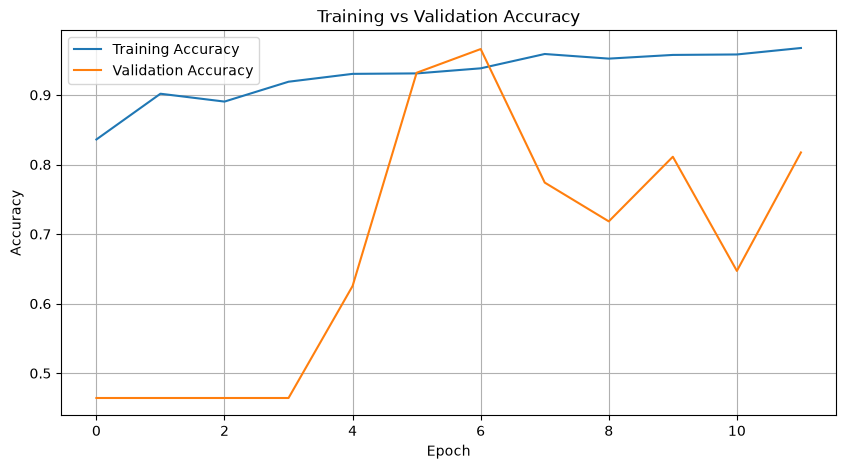

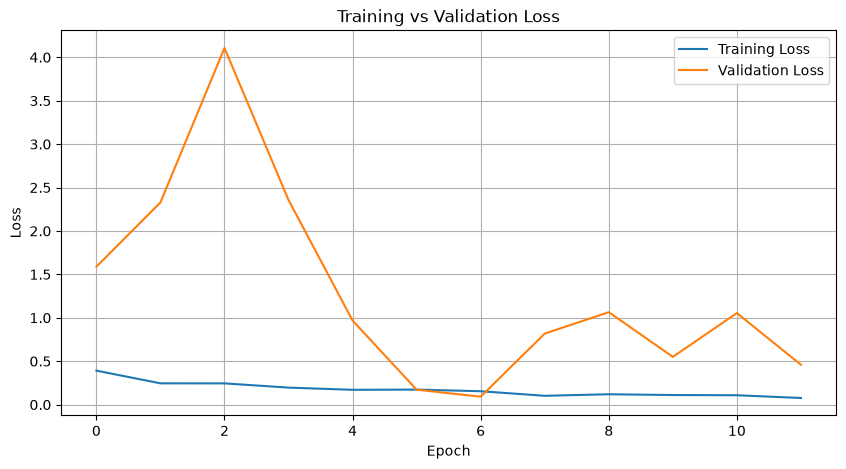

In [22]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Loss Graph
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
best_model = tf.keras.models.load_model(
    checkpoint_path
)

print("Best model loaded successfully!")

print("Model Input Shape:", best_model.input_shape)
print("Model Output Shape:", best_model.output_shape)

Best model loaded successfully!
Model Input Shape: (None, 128, 128, 3)
Model Output Shape: (None, 3)


21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
Best Model Validation Accuracy: 96.59 %

Classification Report:

                       precision    recall  f1-score   support

Potato___Early_blight       1.00      0.95      0.97       150
 Potato___Late_blight       0.94      0.99      0.96       150
     Potato___healthy       0.92      0.96      0.94        23

             accuracy                           0.97       323
            macro avg       0.95      0.96      0.96       323
         weighted avg       0.97      0.97      0.97       323



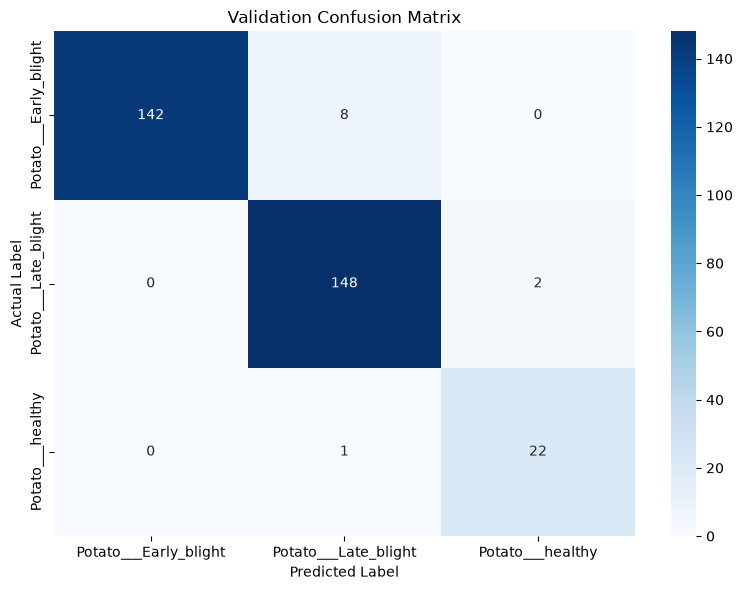

In [24]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import seaborn as sns
import matplotlib.pyplot as plt

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

# Predicted probabilities
y_prob = best_model.predict(val_ds)

# Predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Validation accuracy
print(
    "Best Model Validation Accuracy:",
    round(accuracy_score(y_true, y_pred) * 100, 2), "%"
)

# Classification Report
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [2]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

# Project paths
PROJECT_PATH = os.path.expanduser(
    "~/Potato_Disease_Detection"
)

DATASET_PATH = os.path.join(
    PROJECT_PATH, "dataset"
)

MODEL_PATH = os.path.join(
    PROJECT_PATH,
    "models",
    "best_potato_model.keras"
)

# Class mapping
classes = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

class_to_index = {
    name: index
    for index, name in enumerate(classes)
}

# Load previously saved test and validation data
test_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "test_data.csv")
)

val_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "validation_data.csv")
)

# Image preprocessing
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    image = tf.image.resize(
        image, IMAGE_SIZE
    )

    return image, tf.cast(label, tf.int32)


# Dataset creation
def create_dataset(dataframe, shuffle=False):

    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map(
        class_to_index
    ).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


# Recreate validation and test datasets
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

# Load previously trained model
best_model = tf.keras.models.load_model(
    MODEL_PATH
)

print("Recovery Successful!")
print("Saved CNN model loaded.")
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Recovery Successful!
Saved CNN model loaded.
Validation images: 323
Test images: 323


In [3]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL TEST RESULTS")

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9690 - loss: 0.0810

FINAL TEST RESULTS
Test Loss: 0.081
Test Accuracy: 96.9 %


21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
Test Accuracy: 96.9 %

FINAL TEST CLASSIFICATION REPORT

                       precision    recall  f1-score   support

Potato___Early_blight       1.00      0.96      0.98       150
 Potato___Late_blight       0.94      1.00      0.97       150
     Potato___healthy       1.00      0.83      0.90        23

             accuracy                           0.97       323
            macro avg       0.98      0.93      0.95       323
         weighted avg       0.97      0.97      0.97       323



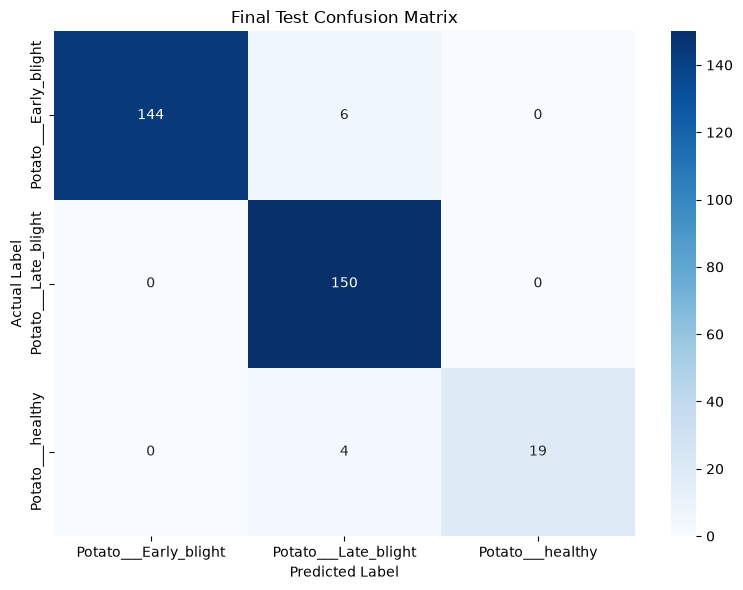

In [4]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Actual test labels
y_test = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Predicted probabilities
test_probabilities = best_model.predict(test_ds)

# Predicted class labels
y_test_pred = np.argmax(
    test_probabilities,
    axis=1
)

# Accuracy
print(
    "Test Accuracy:",
    round(accuracy_score(y_test, y_test_pred) * 100, 2),
    "%"
)

# Classification Report
print("\nFINAL TEST CLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

# Confusion Matrix
test_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [5]:
import os
import json
import shutil

# Create models directory
MODEL_DIR = os.path.join(PROJECT_PATH, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Save final model
FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "potato_disease_model.keras"
)

best_model.save(FINAL_MODEL_PATH)

# Save class names and mapping
class_info = {
    "class_names": classes,
    "class_to_index": class_to_index,
    "image_size": [128, 128]
}

CLASS_PATH = os.path.join(
    MODEL_DIR,
    "class_names.json"
)

with open(CLASS_PATH, "w") as file:
    json.dump(class_info, file, indent=4)

print("Final model saved successfully!")
print("Class mapping saved successfully!")

print("\nSaved Files:")
print(FINAL_MODEL_PATH)
print(CLASS_PATH)

Final model saved successfully!
Class mapping saved successfully!

Saved Files:
/Users/siddharth/Potato_Disease_Detection/models/potato_disease_model.keras
/Users/siddharth/Potato_Disease_Detection/models/class_names.json


In [6]:
import random
import matplotlib.pyplot as plt
import numpy as np

# Select one random image from test dataset
sample = test_df.sample(n=1, random_state=42).iloc[0]

image_path = sample["image_path"]
actual_label = sample["label"]

print("Selected Image:", image_path)
print("Actual Class:", actual_label)

Selected Image: /Users/siddharth/Potato_Disease_Detection/dataset/Potato___Early_blight/dcb9073d-df5b-4a15-aecf-1c3af587cd74___RS_Early.B 8982.JPG
Actual Class: Potato___Early_blight


In [7]:
def predict_leaf(image_path):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.convert_image_dtype(
        image, tf.float32
    )

    image = tf.image.resize(
        image, (128, 128)
    )

    image = tf.expand_dims(image, axis=0)

    predictions = best_model.predict(
        image, verbose=0
    )

    predicted_index = np.argmax(predictions[0])

    predicted_class = classes[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    return predicted_class, confidence, predictions[0]


predicted_class, confidence, probabilities = predict_leaf(
    image_path
)

print("Actual Class:", actual_label)
print("Predicted Class:", predicted_class)
print("Confidence:", round(float(confidence), 2), "%")

Actual Class: Potato___Early_blight
Predicted Class: Potato___Early_blight
Confidence: 99.64 %


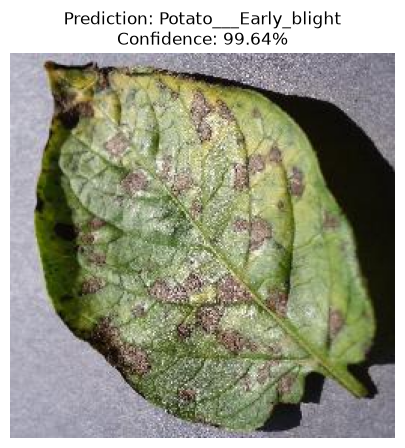

In [8]:
plt.figure(figsize=(6, 5))

plt.imshow(plt.imread(image_path))

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()